# Does the explicit-mention rewrite help the facts the model actually learned?

**Companion to `translation_by_property.ipynb`.** That notebook audited the
explicit-mention corpus rewrite across all 13 931 scoreable PopQA facts and found
recall falls 3.96% -> 2.61%. This one asks a sharper question: *what happens to the
facts the corpus actually attests?*

## The cut

`num_shared_chunks` counts training chunks containing **both** the subject and the
answer -- the places the fact itself could be learned. It is the exposure variable
that dominates everything in the sister forgetting sub-project: learnability tracks
it at r ~ 0.91 per relation, and `log num_shared_chunks` alone predicts natural
forgetting better than any internal signal the model exposes (within-checkpoint
AUC 0.698, vs 0.691 for representational margin).

The **top decile is `num_shared_chunks >= 42`** (the 90th percentile of PopQA-KAS is
42.7). That is the same slice the forgetting notebooks run on, so the cohorts line
up. It is 9.4% of scoreable rows -- and it holds **49% of every fact the baseline
model gets right**.

## Why this is the interesting cut

The rewrite's stated purpose is to make entity mentions unambiguous so knowledge is
easier to acquire. If it works anywhere, it should work where the evidence is
densest. And a corpus intervention that damages only unlearnable tail facts is
cheap; one that damages the head is not.

## Headline

Three findings, in order of how much they should change your mind:

1. **The damage is almost entirely in the head.** −10.00pp (20.61% -> 10.61%) on the
   top decile against −0.44pp on the remaining 12 621 facts. Half of what the
   baseline knew is gone.
2. **But exposure buys no protection, and no penalty either.** Conditional on the
   baseline getting a fact right, survival is 28.1% in the head vs 22.4% in the tail
   -- statistically indistinguishable (Fisher p = 0.14). The head loses more only
   because it had more. The single best predictor of surviving *natural* forgetting
   does nothing against a corpus rewrite.
3. **Both apparent bright spots are verbosity artifacts.** `genre` +15.07pp
   **inverts to −2.74pp** when generations are truncated to three words, and
   `capital of` -- the parent notebook's clean internal control, "unmoved despite a
   high baseline" -- is **−8.85pp (q = 0.030)** under the same truncation. Its
   immunity was length, not knowledge.

## 1. Setup

In [1]:
import os, re, sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

REPO = Path.cwd()
while not (REPO / "explicit_mentions").is_dir() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "explicit_mentions"))
os.environ.setdefault("HF_HUB_OFFLINE", "1")          # popqa-kas is cached locally

from emlib import lment_popqa as L                    # the olmes scorer, for section 6

RECALL = REPO / "data" / "artifacts" / "recall"
BASE_PQ = RECALL / "regular_corpus" / "LMEnt-170M-1E" / "recall_step109672_15shot_recallonly.parquet"
EXPL_PQ = RECALL / "explicit_mention_corpus" / "explicit_170M_1E" / "recall_step113720_15shot_recallonly.parquet"

THRESHOLD = 42          # 90th percentile of num_shared_chunks over PopQA-KAS
print(REPO)

C:\Users\rotem\master\nlp\NLPFinalProject


In [2]:
# Palette shared with the other notebooks in this repo. BLUE = regular corpus,
# ORANGE = translated corpus; they are also the validated diverging pair for the
# signed-delta charts (OKLab dE 33.6 normal, 24.5 worst-case CVD).
#
# NOTE: the parent notebook pairs BLUE with PURPLE #7b5ea7 in its truncation
# figure. That pair FAILS the separation checks -- OKLab dE 12.0 normal (floor 15)
# and 7.4 under deuteranopia (floor 8). SLATE below is the replacement used here:
# dE 17.3 normal / 10.3 worst-case CVD against BLUE, and neutral chroma reads
# naturally as "the control scorer".
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, SLATE, NEUTRAL = "#2a78d6", "#eb6834", "#6e6d69", "#f0efec"
BETTER, WORSE = BLUE, ORANGE

plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
pp = lambda x: f"{100*x:+.2f}pp"

## 2. Load, verify the pairing, and cut the cohort

Same two artifacts as the parent notebook, and the same assertions. If any fires,
every McNemar test below is invalid.

In [3]:
COLS = ["id", "step", "correct", "excluded", "prompt", "generation"]
base = pd.read_parquet(BASE_PQ, columns=COLS)
expl = pd.read_parquet(EXPL_PQ, columns=COLS)

assert (base.id.values == expl.id.values).all(),             "fact order differs"
assert (base.prompt.values == expl.prompt.values).all(),     "prompts differ -> not a corpus-only comparison"
assert (base.excluded.values == expl.excluded.values).all(), "exclusion masks differ"
print(f"{len(base):,} facts, identical prompts, steps {base.step.iloc[0]} (base) vs {expl.step.iloc[0]} (explicit)")

14,248 facts, identical prompts, steps 109672 (base) vs 113720 (explicit)


### Loading the fact table without loading the corpus index

`emlib.data.load_popqa_df()` calls `datasets.load_dataset(...).to_pandas()`, which
materialises **every** column of popqa-kas -- including `subject_chunks`,
`answer_chunks` and `shared_chunks`, three list-of-int columns holding the full
chunk-ID index. That is ~4.3 GB of Arrow, and on a machine already running a
notebook kernel it thrashes rather than loads.

Every column this notebook needs is scalar. Reading them straight off the
memory-mapped cache takes ~2 s and ~0.7 MB. `num_shared_chunks` is a precomputed
scalar, so nothing is lost by skipping the list columns.

In [4]:
def load_popqa_slim(cols=("id", "subj", "prop", "obj", "prop_id",
                          "possible_answers", "num_shared_chunks")):
    # popqa-kas with only the scalar columns -- see the note above. Reproduces
    # load_popqa_df() exactly on these columns, including its dropna of the three
    # rows with a null subj/obj (14 267 -> 14 264).
    import glob
    root = os.environ.get("HF_DATASETS_CACHE") or (
        Path(os.environ.get("HF_HOME", Path.home() / ".cache" / "huggingface")) / "datasets")
    pat = str(Path(root) / "dhgottesman___popqa-kas" / "default" / "*"
              / "*" / "popqa-kas-train-*.arrow")
    files = sorted(glob.glob(pat))
    if not files:
        raise FileNotFoundError(f"no cached popqa-kas arrow shards under {pat}")
    tabs = []
    for f in files:
        src = pa.memory_map(f, "rb")
        try:
            reader = pa.ipc.open_stream(src)
        except pa.ArrowInvalid:
            src.seek(0); reader = pa.ipc.open_file(src)
        tabs.append(reader.read_all().select(list(cols)))
    return (pa.concat_tables(tabs).to_pandas()
              .dropna(subset=["subj", "obj"]).reset_index(drop=True))

qa = load_popqa_slim()
assert len(qa) == 14264, f"expected 14264 popqa-kas rows, got {len(qa)}"
print(f"{len(qa):,} facts, {len(qa.columns)} columns")

14,264 facts, 7 columns


In [5]:
df = (base.rename(columns={"correct": "base", "generation": "g_base"})[["id", "base", "excluded", "g_base"]]
        .merge(expl.rename(columns={"correct": "expl", "generation": "g_expl"})[["id", "expl", "g_expl"]], on="id")
        .merge(qa, on="id"))
df = df[~df.excluded].reset_index(drop=True)

# `is_head`, not `head` -- a column named `head` shadows DataFrame.head and makes
# df[df.head] raise a confusing positional-indexing TypeError.
df["is_head"] = df.num_shared_chunks >= THRESHOLD
top  = df[df.is_head].reset_index(drop=True)
rest = df[~df.is_head].reset_index(drop=True)

print(f"{len(df):,} scoreable facts")
print(f"90th percentile of num_shared_chunks over all of PopQA-KAS: {qa.num_shared_chunks.quantile(0.90):.1f}")
print(f"head (num_shared_chunks >= {THRESHOLD}): {len(top):,} facts "
      f"= {len(top)/len(df):.1%} of rows, {top.prop.nunique()} relations")
print(f"tail:                                   {len(rest):,} facts")

13,931 scoreable facts
90th percentile of num_shared_chunks over all of PopQA-KAS: 42.7
head (num_shared_chunks >= 42): 1,310 facts = 9.4% of rows, 15 relations
tail:                                   12,621 facts


In [6]:
print("exposure distribution (scoreable facts):")
print(df.num_shared_chunks.describe(percentiles=[.25, .5, .75, .9, .95]).to_string())

print(f"\nthe head is {len(top)/len(df):.1%} of rows but holds "
      f"{top.base.sum()/df.base.sum():.1%} of everything the BASELINE gets right "
      f"({int(top.base.sum())}/{int(df.base.sum())})")
print(f"                              and {top.expl.sum()/df.expl.sum():.1%} of what the "
      f"TRANSLATED model gets right ({int(top.expl.sum())}/{int(df.expl.sum())})")

print("\nhead cohort by relation:")
print(top.prop.value_counts().to_string())

exposure distribution (scoreable facts):
count     13931.000000
mean        170.476922
std        2160.817662
min           0.000000
25%           1.000000
50%           3.000000
75%          10.000000
90%          38.000000
95%         143.500000
max      101081.000000

the head is 9.4% of rows but holds 49.0% of everything the BASELINE gets right (270/551)
                              and 38.2% of what the TRANSLATED model gets right (139/364)

head cohort by relation:
prop
capital           385
capital of        192
religion          107
country           106
father             82
genre              73
sport              65
composer           61
author             60
producer           58
screenwriter       41
director           38
mother             29
place of birth      9
occupation          4


The head is a different mix of relations from the corpus as a whole: `capital` (385)
and `capital of` (192) alone are 44% of it, because capital cities co-occur with
their countries constantly. Nine relations contribute fewer than 70 facts each, so
per-relation claims below are thin outside the top few.

## 3. The overall effect, head vs tail

In [7]:
def paired(g, label):
    b, e = g.base.mean(), g.expl.mean()
    n01 = int(((g.base == 0) & (g.expl == 1)).sum())   # gained by translation
    n10 = int(((g.base == 1) & (g.expl == 0)).sum())   # lost to translation
    p = stats.binomtest(n01, n01 + n10, 0.5).pvalue if (n01 + n10) else 1.0
    rel = (e - b) / b if b else np.nan
    print(f"{label:<22} n={len(g):>6,}   {b:.4f} -> {e:.4f}   {pp(e-b)}  "
          f"(relative {100*rel:+.1f}%)   gained {n01:>3} lost {n10:>3}   McNemar p = {p:.3g}")
    return dict(n=len(g), base=b, expl=e, delta=e-b, gained=n01, lost=n10, p=p)

r_all  = paired(df,   "all scoreable")
r_head = paired(top,  f"head (>= {THRESHOLD})")
r_tail = paired(rest, f"tail (< {THRESHOLD})")

all scoreable          n=13,931   0.0396 -> 0.0261   -1.34pp  (relative -33.9%)   gained 225 lost 412   McNemar p = 1.15e-13
head (>= 42)           n= 1,310   0.2061 -> 0.1061   -10.00pp  (relative -48.5%)   gained  63 lost 194   McNemar p = 1.06e-16
tail (< 42)            n=12,621   0.0223 -> 0.0178   -0.44pp  (relative -19.9%)   gained 162 lost 218   McNemar p = 0.00472


In [8]:
# Is the corpus effect actually DIFFERENT between head and tail, or just bigger
# because the head has more to lose? Compare the composition of discordant pairs:
# P(gain | the fact flipped) is a headroom-free summary of which way flips go.
tab = np.array([[r_head["gained"], r_head["lost"]],
                [r_tail["gained"], r_tail["lost"]]])
chi2, p_int, _, _ = stats.chi2_contingency(tab)

for lab, r in [("head", r_head), ("tail", r_tail)]:
    n01, n10 = r["gained"], r["lost"]
    ci = stats.binomtest(n01, n01 + n10, 0.5).proportion_ci()
    print(f"{lab}: P(gain | discordant) = {n01/(n01+n10):.3f}  [{ci.low:.3f}-{ci.high:.3f}]   ({n01}/{n01+n10})")
print(f"\ndifference in discordant composition: chi2 p = {p_int:.3g}")

head: P(gain | discordant) = 0.245  [0.194-0.302]   (63/257)
tail: P(gain | discordant) = 0.426  [0.376-0.478]   (162/380)

difference in discordant composition: chi2 p = 4.05e-06


Flips in the head run against the rewrite about three to one (24.5% of flips are
gains); in the tail they are near even (42.6%). The difference is real
(chi2 p = 4.0e-06). So this is not only a headroom story at the *flip* level -- when
a well-attested fact changes state under the rewrite, it is much more likely to be
changing for the worse.

§5 shows the important qualification: that asymmetry comes from the head's much
larger stock of correct facts entering the flip pool, not from a higher per-fact
destruction rate.

             n  acc_base  acc_expl   delta  delta_pp
bin                                                 
0         2428    0.0177    0.0165 -0.0012   -0.1236
1         2280    0.0320    0.0211 -0.0110   -1.0965
2-3       2691    0.0234    0.0197 -0.0037   -0.3716
4-7       2381    0.0151    0.0130 -0.0021   -0.2100
8-13      1412    0.0212    0.0177 -0.0035   -0.3541
14-41     1429    0.0252    0.0196 -0.0056   -0.5598
42-127     577    0.0468    0.0468  0.0000    0.0000
128-1023   450    0.2000    0.1067 -0.0933   -9.3333
1024+      283    0.5406    0.2261 -0.3145  -31.4488


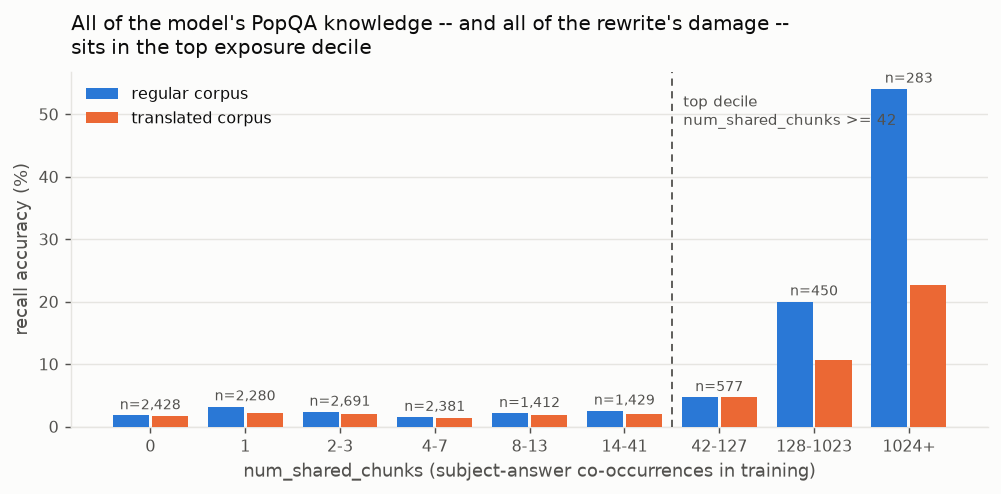

In [9]:
# FIG 1 -- accuracy under each corpus across the exposure range.
# Fixed bin edges (not qcut): num_shared_chunks is massively tied at small values,
# so quantile bins collapse. The threshold falls exactly on a bin boundary.
edges = [-1, 0, 1, 3, 7, 13, 41, 127, 1023, np.inf]
labs  = ["0", "1", "2-3", "4-7", "8-13", "14-41", "42-127", "128-1023", "1024+"]
df["bin"] = pd.cut(df.num_shared_chunks, edges, labels=labs)

b = df.groupby("bin", observed=True).agg(n=("base", "size"), acc_base=("base", "mean"),
                                         acc_expl=("expl", "mean"))
b["delta"] = b.acc_expl - b.acc_base
print(b.assign(delta_pp=100*b.delta).to_string(float_format=lambda x: f"{x:.4f}"))

x = np.arange(len(b)); w, gap = 0.38, 0.015
fig, ax = plt.subplots(figsize=(7.8, 3.9))
ax.bar(x - w/2 - gap, 100*b.acc_base, w, color=BLUE,   label="regular corpus", zorder=3)
ax.bar(x + w/2 + gap, 100*b.acc_expl, w, color=ORANGE, label="translated corpus", zorder=3)
ax.axvline(5.5, color=INK2, lw=1, ls=(0, (4, 3)), zorder=4)
ax.text(5.62, ax.get_ylim()[1]*0.94, f"top decile\nnum_shared_chunks >= {THRESHOLD}",
        fontsize=8.5, color=INK2, va="top")
ax.set_xticks(x); ax.set_xticklabels(b.index)
ax.set_xlabel("num_shared_chunks (subject-answer co-occurrences in training)")
ax.set_ylabel("recall accuracy (%)")
ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.set_title("All of the model's PopQA knowledge -- and all of the rewrite's damage --\n"
             "sits in the top exposure decile", loc="left", pad=10)
ax.legend(fontsize=9, loc="upper left")
for xi, (v, n) in enumerate(zip(b.acc_base, b.n)):
    ax.text(xi, 100*v + 1.0, f"n={n:,}", ha="center", fontsize=7.5, color=INK2)
plt.tight_layout(); plt.show()

Below 14 co-occurrences both models sit at 1-3% and the two corpora are
indistinguishable -- a 170M model at one epoch has learned essentially nothing there,
so those 9 000-odd facts cannot inform the comparison in either direction. Accuracy
only lifts off in the last two bins, and that is exactly where the orange bar
collapses.

## 4. Per-relation effect inside the head

In [10]:
def per_prop(frame, base_col="base", expl_col="expl"):
    rows = []
    for prop, g in frame.groupby("prop"):
        g01 = int(((~g[base_col]) & (g[expl_col])).sum())
        g10 = int(((g[base_col]) & (~g[expl_col])).sum())
        p = stats.binomtest(g01, g01 + g10, 0.5).pvalue if (g01 + g10) else 1.0
        rows.append(dict(prop=prop, n=len(g), acc_base=g[base_col].mean(), acc_expl=g[expl_col].mean(),
                         delta=g[expl_col].mean() - g[base_col].mean(), gained=g01, lost=g10, p=p))
    out = pd.DataFrame(rows).sort_values("delta", ascending=False).reset_index(drop=True)
    out["q_bh"] = stats.false_discovery_control(out.p.values)
    out["sig"] = np.where(out.q_bh < 0.05, "*", "")
    return out

pp_head = per_prop(top)
pp_all  = per_prop(df)
pp_head.style.format({"acc_base": "{:.3f}", "acc_expl": "{:.3f}", "delta": "{:+.3f}",
                      "p": "{:.2g}", "q_bh": "{:.2g}"}).hide(axis="index")

prop,n,acc_base,acc_expl,delta,gained,lost,p,q_bh,sig
genre,73,0.041,0.192,+0.151,12,1,0.0034,0.017,*
producer,58,0.000,0.052,+0.052,3,0,0.25,0.94,
screenwriter,41,0.024,0.073,+0.049,3,1,0.62,1,
mother,29,0.000,0.034,+0.034,1,0,1,1,
composer,61,0.000,0.016,+0.016,1,0,1,1,
director,38,0.000,0.000,+0.000,0,0,1,1,
father,82,0.000,0.000,+0.000,0,0,1,1,
place of birth,9,0.000,0.000,+0.000,0,0,1,1,
occupation,4,0.000,0.000,+0.000,0,0,1,1,
sport,65,0.123,0.123,+0.000,5,5,1,1,


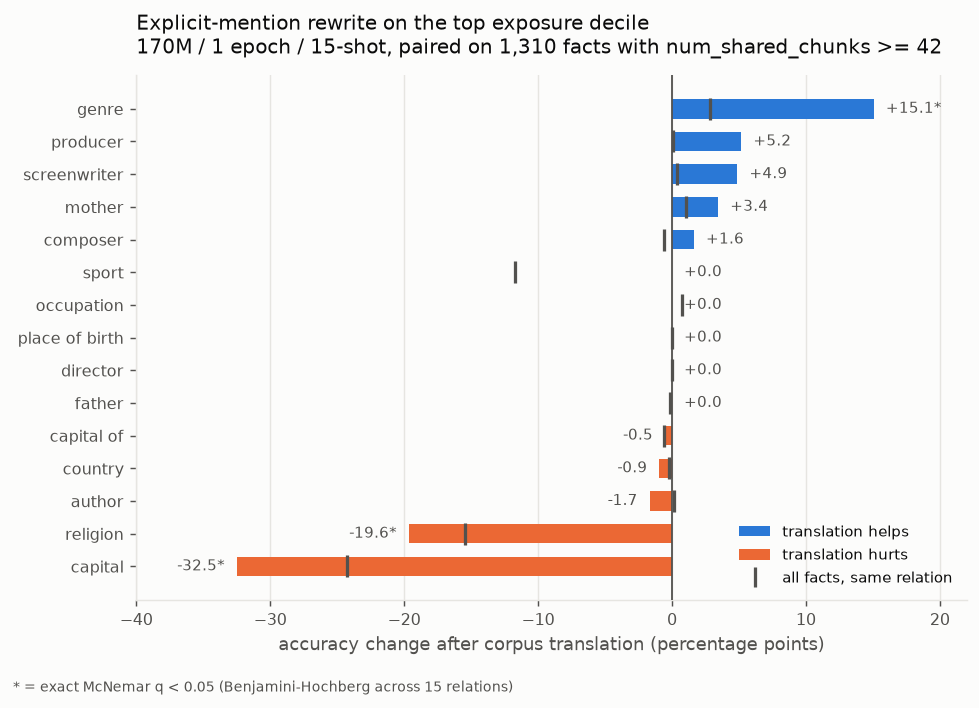

In [11]:
# FIG 2 -- head-cohort delta per relation, with the all-facts delta as a reference tick.
d = pp_head.sort_values("delta")
ref = pp_all.set_index("prop").delta.reindex(d.prop).values

fig, ax = plt.subplots(figsize=(7.6, 5.4))
colors = [BETTER if v > 0 else (WORSE if v < 0 else GRID) for v in d.delta]
ax.barh(d.prop, 100*d.delta, color=colors, height=0.6, zorder=3)
ax.scatter(100*ref, np.arange(len(d)), marker="|", s=150, linewidths=1.8,
           color=INK2, zorder=5, label="same relation, all 13 931 facts")
ax.axvline(0, color=INK2, lw=1, zorder=4)
ax.xaxis.grid(True); ax.set_axisbelow(True)

for y, (v, n, s) in enumerate(zip(d.delta, d.n, d.sig)):
    off = 0.9 if v >= 0 else -0.9
    ax.text(100*v + off, y, f"{100*v:+.1f}{s}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)

ax.set_xlim(-40, 22)
ax.set_xlabel("accuracy change after corpus translation (percentage points)")
ax.set_title(f"Explicit-mention rewrite on the top exposure decile\n"
             f"170M / 1 epoch / 15-shot, paired on {len(top):,} facts with "
             f"num_shared_chunks >= {THRESHOLD}", loc="left", pad=12)
ax.legend(handles=[Patch(facecolor=BETTER, label="translation helps"),
                   Patch(facecolor=WORSE,  label="translation hurts"),
                   plt.Line2D([], [], marker="|", linestyle="none", markersize=11,
                              markeredgewidth=1.8, color=INK2, label="all facts, same relation")],
          loc="lower right", fontsize=8.5)   # the two biggest losers occupy lower-LEFT
fig.text(0.015, 0.005, "* = exact McNemar q < 0.05 (Benjamini-Hochberg across 15 relations)",
         fontsize=8, color=INK2)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

### 4.1 What moved relative to the all-facts audit

| relation | head n | head delta | all-facts delta | reading |
|---|---|---|---|---|
| `capital` | 385 | **−32.5pp** | −24.3pp | the collapse is entirely a head phenomenon (tail `capital` sits at 1.5% baseline) |
| `religion` | 107 | **−19.6pp** | −15.5pp | worse in the head, and the head baseline was higher (35.5%) |
| `genre` | 73 | **+15.1pp** | +2.9pp | the "gain" is 5x larger here -- and §6 kills it |
| `sport` | 65 | 0.0pp | −11.7pp | **flat in the head**; all of the sport damage is in the tail (−13.4pp) |
| `capital of` | 192 | −0.5pp | −0.6pp | unmoved at the shipped scorer -- but see §6 |
| `country` | 106 | −0.9pp | −0.3pp | unmoved |

`sport` is the surprise. Well-attested sport facts start *lower* than tail sport
facts (12.3% vs 24.6%) and are untouched, while the tail loses more than half of its
24.6%. The baseline's tail score came from answering plain `"football"`, which the
scorer accepts as an alias of the 62%-modal gold `association football`; the head is
dense in rugby, cricket and motorsport subjects where that free ride does not apply.
So `sport` in the parent notebook is largely a story about one lucky default, and it
does not survive the exposure cut.

In [12]:
for prop in ["capital", "capital of", "country", "religion", "sport", "genre"]:
    for lab, g in [("head", df[(df.prop == prop) & df.is_head]),
                   ("tail", df[(df.prop == prop) & ~df.is_head])]:
        if len(g):
            print(f"  {prop:<11} {lab}: n={len(g):>5}  {g.base.mean():.3f} -> {g.expl.mean():.3f}   "
                  f"{pp(g.expl.mean() - g.base.mean())}")
    print()

  capital     head: n=  385  0.400 -> 0.075   -32.47pp
  capital     tail: n=  134  0.015 -> 0.007   -0.75pp

  capital of  head: n=  192  0.266 -> 0.260   -0.52pp
  capital of  tail: n=  122  0.016 -> 0.008   -0.82pp

  country     head: n=  106  0.123 -> 0.113   -0.94pp
  country     tail: n=  694  0.141 -> 0.140   -0.14pp

  religion    head: n=  107  0.355 -> 0.159   -19.63pp
  religion    tail: n=  223  0.193 -> 0.058   -13.45pp

  sport       head: n=   65  0.123 -> 0.123   +0.00pp
  sport       tail: n=  447  0.246 -> 0.112   -13.42pp

  genre       head: n=   73  0.041 -> 0.192   +15.07pp
  genre       tail: n= 1538  0.005 -> 0.027   +2.28pp



In [13]:
r = stats.spearmanr(pp_head.acc_base, pp_head.delta)
print(f"Spearman(baseline accuracy, delta) across head relations = {r.statistic:+.3f}  p={r.pvalue:.3g}")
print("(the same statistic over all facts was -0.832)")

Spearman(baseline accuracy, delta) across head relations = -0.594  p=0.0195
(the same statistic over all facts was -0.832)


Headroom still explains a lot of the ranking (−0.59), but noticeably less than in the
full audit (−0.83) -- because the head cohort removes most of the floor-bound
relations that made the correlation trivially strong. `capital of` at a 26.6%
baseline and unmoved, next to `capital` at 40.0% and annihilated, remains the
cleanest internal contrast in the experiment.

## 5. The headroom control: does exposure protect a fact?

§3 established the head loses ten times more accuracy in absolute terms. That is
compatible with two very different worlds:

* **A.** The rewrite is *especially* corrosive to well-attested facts -- dense
  co-occurrence built a representation the rewrite specifically breaks.
* **B.** The rewrite destroys a fixed fraction of whatever the model knew, and the
  head simply held most of the knowledge.

These are separated by conditioning on the baseline being right. Under A, survival
falls with exposure; under B it is flat.

In [14]:
print("P(translated correct | regular correct)  -- survival")
print("P(translated correct | regular wrong)    -- acquisition\n")
for lab, g in [(f"head (>= {THRESHOLD})", top), (f"tail (< {THRESHOLD})", rest), ("all", df)]:
    c, w = g[g.base], g[~g.base]
    print(f"  {lab:<16} survival {c.expl.mean():.3f} ({int(c.expl.sum())}/{len(c)})    "
          f"acquisition {w.expl.mean():.4f} ({int(w.expl.sum())}/{len(w)})")

c1, c2 = top[top.base], rest[rest.base]
odds, p_f = stats.fisher_exact([[int(c1.expl.sum()), len(c1) - int(c1.expl.sum())],
                                [int(c2.expl.sum()), len(c2) - int(c2.expl.sum())]])
print(f"\nsurvival, head vs tail: Fisher exact p = {p_f:.3f}  (odds ratio {odds:.2f})")

P(translated correct | regular correct)  -- survival
P(translated correct | regular wrong)    -- acquisition

  head (>= 42)     survival 0.281 (76/270)    acquisition 0.0606 (63/1040)
  tail (< 42)      survival 0.224 (63/281)    acquisition 0.0131 (162/12340)
  all              survival 0.252 (139/551)    acquisition 0.0168 (225/13380)

survival, head vs tail: Fisher exact p = 0.141  (odds ratio 1.36)


In [15]:
# Same question as a gradient rather than a split: among facts the baseline got
# right, does survival trend with exposure at all?
d = df[df.base].copy()
d["q5"] = pd.qcut(d.num_shared_chunks.rank(method="first"), 5, labels=False)
print("survival among the 551 base-correct facts, by exposure quintile:")
for q, g in d.groupby("q5"):
    print(f"  quintile {q}  num_shared_chunks [{g.num_shared_chunks.min():>6}-{g.num_shared_chunks.max():>6}]  "
          f"n={len(g):>4}  survival {g.expl.mean():.3f}")
r = stats.spearmanr(d.num_shared_chunks, d.expl.astype(int))
print(f"\nSpearman(num_shared_chunks, survives) = {r.statistic:+.3f}  p={r.pvalue:.3g}")

t = top.copy(); t["t3"] = pd.qcut(t.num_shared_chunks, 3, labels=False)
print("\nwithin the head, absolute damage vs conditional survival:")
for k, g in t.groupby("t3"):
    c = g[g.base]
    print(f"  tertile {k} [{g.num_shared_chunks.min():>6}-{g.num_shared_chunks.max():>6}]  n={len(g)}  "
          f"acc {g.base.mean():.3f} -> {g.expl.mean():.3f} ({pp(g.expl.mean()-g.base.mean())})   "
          f"survival {c.expl.mean():.3f} on {len(c)} correct")

survival among the 551 base-correct facts, by exposure quintile:
  quintile 0  num_shared_chunks [     0-     1]  n= 111  survival 0.180
  quintile 1  num_shared_chunks [     1-     8]  n= 110  survival 0.300
  quintile 2  num_shared_chunks [     8-   226]  n= 110  survival 0.218
  quintile 3  num_shared_chunks [   238-  2364]  n= 110  survival 0.236
  quintile 4  num_shared_chunks [  2391-101081]  n= 110  survival 0.327

Spearman(num_shared_chunks, survives) = +0.084  p=0.0476

within the head, absolute damage vs conditional survival:
  tertile 0 [    42-    88]  n=438  acc 0.046 -> 0.048 (+0.23pp)   survival 0.300 on 20 correct
  tertile 1 [    89-   391]  n=435  acc 0.133 -> 0.078 (-5.52pp)   survival 0.259 on 58 correct
  tertile 2 [   394-101081]  n=437  acc 0.439 -> 0.192 (-24.71pp)   survival 0.286 on 192 correct


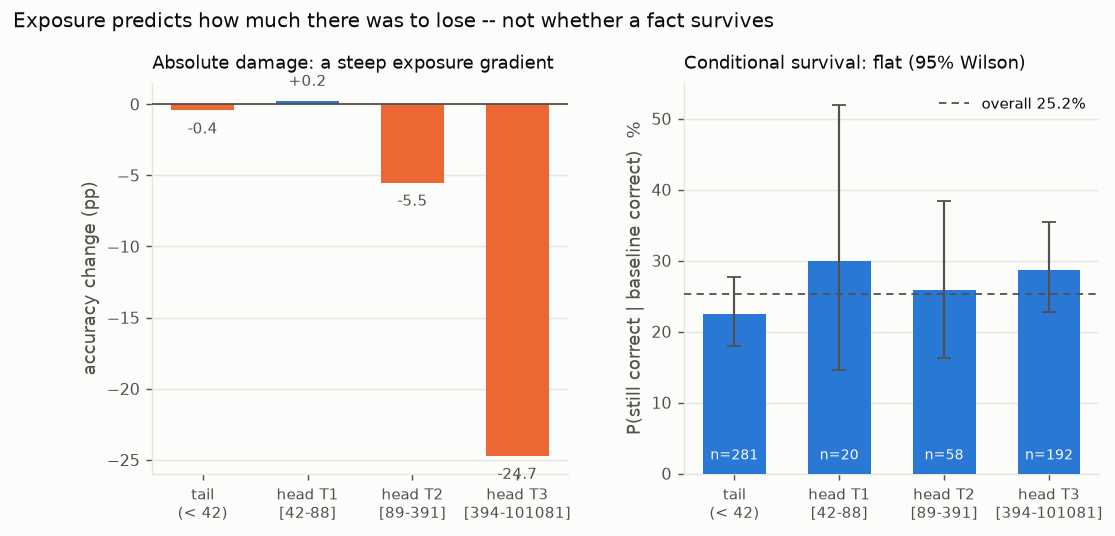

In [16]:
# FIG 3 -- the control. Absolute delta looks like a strong exposure gradient;
# conditional survival is flat.
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    ph = k / n; d = 1 + z**2/n
    c = (ph + z**2/(2*n)) / d
    h = z*np.sqrt(ph*(1-ph)/n + z**2/(4*n**2)) / d
    return c - h, c + h

groups = [("tail\n(< 42)", rest)] + [
    (f"head T{k+1}\n[{g.num_shared_chunks.min()}-{g.num_shared_chunks.max()}]", g)
    for k, g in t.groupby("t3")]

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), gridspec_kw={"wspace": 0.28})
xs = np.arange(len(groups))

deltas = [100*(g.expl.mean() - g.base.mean()) for _, g in groups]
axes[0].bar(xs, deltas, 0.6, color=[BETTER if v > 0 else WORSE for v in deltas], zorder=3)
axes[0].axhline(0, color=INK2, lw=1, zorder=4)
axes[0].set_ylabel("accuracy change (pp)")
axes[0].set_title("Absolute damage: a steep exposure gradient", loc="left", pad=8, fontsize=10)
for xi, v in zip(xs, deltas):
    axes[0].text(xi, v + (0.8 if v >= 0 else -0.8), f"{v:+.1f}", ha="center",
                 va="bottom" if v >= 0 else "top", fontsize=8.5, color=INK2)

surv = [g[g.base].expl.mean() for _, g in groups]
lo_hi = [wilson(int(g[g.base].expl.sum()), int(g.base.sum())) for _, g in groups]
err = np.array([[100*(s - lo) for s, (lo, hi) in zip(surv, lo_hi)],
                [100*(hi - s) for s, (lo, hi) in zip(surv, lo_hi)]])
axes[1].bar(xs, [100*s for s in surv], 0.6, color=BLUE, zorder=3)
axes[1].errorbar(xs, [100*s for s in surv], yerr=err, fmt="none",
                 ecolor=INK2, elinewidth=1.2, capsize=4, zorder=5)
surv_all = df[df.base].expl.mean()
# Labelled via the legend, not an inline text: every free spot on this axes is
# crossed by one of the Wilson whiskers.
axes[1].axhline(100*surv_all, color=INK2, lw=1, ls=(0, (4, 3)), zorder=4,
                label=f"overall {100*surv_all:.1f}%")
axes[1].legend(loc="upper right", fontsize=8.5)
axes[1].set_ylabel("P(still correct | baseline correct)  %")
axes[1].set_ylim(0, 55)
axes[1].set_title("Conditional survival: flat (95% Wilson)", loc="left", pad=8, fontsize=10)
for xi, (s, (_, g)) in enumerate(zip(surv, groups)):
    axes[1].text(xi, 2, f"n={int(g.base.sum())}", ha="center", fontsize=7.5, color=SURF)

for a in axes:
    a.set_xticks(xs); a.set_xticklabels([n for n, _ in groups], fontsize=8.5)
    a.yaxis.grid(True); a.set_axisbelow(True)
fig.suptitle("Exposure predicts how much there was to lose -- not whether a fact survives",
             x=0.011, ha="left", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

**World B.** Survival is 28.1% in the head and 22.4% in the tail -- if anything
*higher* where exposure is densest, and nowhere near significant (Fisher p = 0.14).
Inside the head the absolute delta swings from +0.2pp to −24.7pp across tertiles
while survival stays at 0.300 / 0.259 / 0.286. Across all 551 base-correct facts the
exposure-survival correlation is +0.084 -- a whisper, in the *protective* direction.

This is the notebook's main result, and it is worth stating carefully:

> The explicit-mention rewrite removes roughly three quarters of whatever the
> baseline knew, at a rate that does not depend on how well the corpus attests the
> fact. Exposure determines how much is at stake, not the odds.

That matters because `num_shared_chunks` is the strongest protective factor known in
this project for *natural* forgetting -- hazard falls 46% -> 12% across its quintiles,
and it beats every internal signal at predicting which facts slip. Against a corpus
rewrite it is inert. Whatever the rewrite breaks, it is not the thing repeated
co-occurrence builds.

The one place exposure does help is acquisition: the head picks up new facts at
6.06% vs the tail's 1.31%. But 63 gained against 194 lost is not a trade the
intervention wins, and §6 shows most of those 63 are not knowledge either.

## 6. Truncation control: are the gains real?

The olmes scorer is `max_gen_toks=15`, greedy, stop at `\n\n`, correct iff **any**
gold alias substring-matches the generation. Longer answers get more chances to
contain the gold string by accident. The parent notebook showed this inflated
`genre` corpus-wide; in the head the verbosity gap is far larger, so the control
matters more.

In [17]:
def rescore(frame, col, k):
    # Re-apply the olmes substring scorer to the first k words of a generation.
    return np.array([L.is_correct(r, " ".join(str(r[col]).split()[:k])) for _, r in frame.iterrows()], bool)

for k in (3, 5, 15):
    sb, se = rescore(top, "g_base", k), rescore(top, "g_expl", k)
    print(f"head, first {k:>2d} words:  base {sb.mean():.4f}   translated {se.mean():.4f}   {pp(se.mean()-sb.mean())}")

top["base_k3"], top["expl_k3"] = rescore(top, "g_base", 3), rescore(top, "g_expl", 3)
n01 = int(((~top.base_k3) & top.expl_k3).sum()); n10 = int((top.base_k3 & (~top.expl_k3)).sum())
print(f"\nhead under the 3-word scorer: gained {n01}, lost {n10}, "
      f"exact McNemar p = {stats.binomtest(n01, n01+n10, 0.5).pvalue:.3g}")

head, first  3 words:  base 0.1847   translated 0.0679   -11.68pp


head, first  5 words:  base 0.2000   translated 0.0931   -10.69pp
head, first 15 words:  base 0.2061   translated 0.1061   -10.00pp



head under the 3-word scorer: gained 33, lost 186, exact McNemar p = 4.49e-27


In [18]:
pp_head_k3 = per_prop(top, "base_k3", "expl_k3")
cmp = (pp_head.set_index("prop")[["n", "delta"]].rename(columns={"delta": "delta_full"})
         .join(pp_head_k3.set_index("prop")[["delta", "q_bh"]]
                 .rename(columns={"delta": "delta_first3", "q_bh": "q_bh_first3"}))
         .sort_values("delta_full", ascending=False))
cmp["surviving"] = np.where(cmp.delta_full.abs() > 1e-9, cmp.delta_first3 / cmp.delta_full, np.nan)
cmp.style.format({"delta_full": "{:+.4f}", "delta_first3": "{:+.4f}",
                  "q_bh_first3": "{:.2g}", "surviving": "{:.0%}"})

,n,delta_full,delta_first3,q_bh_first3,surviving
prop,,,,,
genre,73,+0.1507,-0.0274,1,-18%
producer,58,+0.0517,+0.0517,0.86,100%
screenwriter,41,+0.0488,+0.0488,1,100%
mother,29,+0.0345,+0.0345,1,100%
composer,61,+0.0164,+0.0164,1,100%
director,38,+0.0000,+0.0000,1,nan%
father,82,+0.0000,+0.0000,1,nan%
place of birth,9,+0.0000,+0.0000,1,nan%
occupation,4,+0.0000,+0.0000,1,nan%


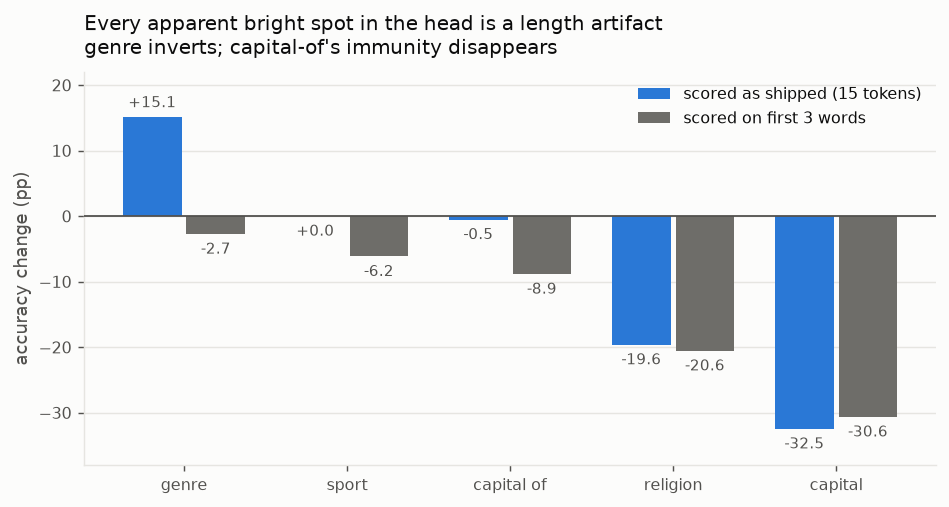

In [19]:
# FIG 4 -- shipped scorer vs 3-word scorer, the relations with anything to say.
sub = cmp.loc[["genre", "sport", "capital of", "religion", "capital"]]
x = np.arange(len(sub)); w, gap = 0.36, 0.015
fig, ax = plt.subplots(figsize=(7.4, 4.0))
ax.bar(x - w/2 - gap, 100*sub.delta_full,   w, color=BLUE,  label="scored as shipped (15 tokens)", zorder=3)
ax.bar(x + w/2 + gap, 100*sub.delta_first3, w, color=SLATE, label="scored on first 3 words", zorder=3)
ax.axhline(0, color=INK2, lw=1, zorder=4)
ax.set_xticks(x); ax.set_xticklabels(sub.index)
ax.set_ylim(-38, 22)
ax.set_ylabel("accuracy change (pp)")
ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.set_title("Every apparent bright spot in the head is a length artifact\n"
             "genre inverts; capital-of's immunity disappears", loc="left", pad=10)
ax.legend(fontsize=9, loc="upper right")
for xs_, vals in [(x - w/2 - gap, sub.delta_full), (x + w/2 + gap, sub.delta_first3)]:
    for xi, v in zip(xs_, vals):
        ax.text(xi, 100*v + (1.0 if v > 0 else -1.2), f"{100*v:+.1f}",
                ha="center", va="bottom" if v > 0 else "top", fontsize=8.5, color=INK2)
plt.tight_layout(); plt.show()

Two corrections come out of this, both sharper than the parent notebook's version:

1. **`genre` +15.07pp inverts to −2.74pp.** Not merely attenuated -- the sign flips.
   Under the 3-word scorer the translated model gains 0 genre facts and loses 2.
   Every one of the 12 apparent gains came from a gold string appearing late in a
   long descriptive continuation.
2. **`capital of` was never immune.** −0.52pp as shipped, **−8.85pp on the first
   three words, and it is significant (q = 0.030)**. The parent notebook's §4.2
   leans on `capital of` and `country` as unmoved high-baseline controls proving the
   damage is not pure headroom. For `capital of` that reading does not hold: the
   relation is being damaged too, and only its extra verbosity keeps the substring
   scorer satisfied. Its modal translated answer is
   `"the world. The city is the capital of the world. The city is"` -- a degenerate
   loop that still happens to contain country names.

The honest head-cohort number is therefore **18.47% -> 6.79%, −11.68pp** (33 gained,
186 lost, p = 4.5e-27) -- worse than the −10.00pp the shipped scorer reports.
`country` moves the other way (+3.77pp truncated) but on 7 gained vs 3 lost, which
is noise.

In [20]:
print("generation length, by cohort")
for lab, g in [("head", top), ("tail", rest)]:
    for name, col in [("regular", "g_base"), ("translated", "g_expl")]:
        wds = g[col].str.split().str.len()
        print(f"  {lab:<5} {name:<11} mean {wds.mean():.2f} words   <=4 words {(wds<=4).mean():>5.1%}   "
              f"degenerate 'in is in is' {(g[col].str.contains('in is in is', regex=False)).mean():>5.1%}")

generation length, by cohort
  head  regular     mean 3.83 words   <=4 words 67.5%   degenerate 'in is in is'  0.0%
  head  translated  mean 7.72 words   <=4 words 43.7%   degenerate 'in is in is'  5.0%
  tail  regular     mean 4.34 words   <=4 words 66.0%   degenerate 'in is in is'  0.0%
  tail  translated  mean 5.10 words   <=4 words 68.4%   degenerate 'in is in is'  0.4%


The verbosity blow-up is a **head phenomenon**: 3.83 -> 7.72 words (2.0x) on
well-attested facts against 4.34 -> 5.10 (1.2x) on the tail, under the same
15-token cap. The share of short answers falls from 67.5% to 43.7% in the head and
does not move at all in the tail. So the rewrite specifically destroys the
translated model's ability to *stop* on the subjects the corpus talks about most --
which is also where the degenerate repeat loop appears (5.0% of head answers vs
0.4% of tail).

## 7. What the failures look like on the facts the corpus attests

In [21]:
for prop in ["capital", "capital of", "religion", "sport", "genre", "country"]:
    g = top[top.prop == prop]
    if not len(g): continue
    print("=" * 100)
    print(f"{prop.upper()}   n={len(g)}   base {g.base.mean():.3f} -> translated {g.expl.mean():.3f}")
    for label, col in [("regular   ", "g_base"), ("translated", "g_expl")]:
        t3 = g[col].str.strip().value_counts().head(3)
        print(f"  most common {label}: " + " | ".join(f"{v!r} x{c}" for v, c in t3.items()))

CAPITAL   n=385   base 0.400 -> translated 0.075
  most common regular   : 'in the United States' x12 | 'in the Philippines' x10 | 'in the South Pacific' x8
  most common translated: 'in is in is in is in is in is in is in is in' x50 | 'in is the capital of the United Kingdom. The capital of the United Kingdom' x6 | 'in is Cape Town' x5
CAPITAL OF   n=192   base 0.266 -> translated 0.260
  most common regular   : 'the United States' x18 | 'the United Kingdom' x13 | 'Spain' x6
  most common translated: 'the world. The city is the capital of the world. The city is' x9 | 'the United States. The city is the capital of the United States. The' x6 | 'the Austrian state of Styria. Vienna is the capital of the Austrian state' x6
RELIGION   n=107   base 0.355 -> translated 0.159
  most common regular   : 'Christianity' x45 | 'Islam' x13 | 'Catholicism' x12
  most common translated: 'Catholicism.' x56 | 'Christianity' x5 | "Hinduism. The author of 'All Things Go' is Jim Carrey" x5
SPORT   n=65   

In [22]:
dg = df.assign(deg=df.g_expl.str.contains("in is in is", regex=False))
print("degenerate repeat-loop rate in the translated model:")
print(f"  head {dg[dg.is_head].deg.mean():.1%}   tail {dg[~dg.is_head].deg.mean():.1%}\n")
print(dg[dg.is_head].groupby("prop").deg.agg(["mean", "size"])
        .sort_values("mean", ascending=False).head(6).to_string(float_format=lambda x: f"{x:.3f}"))

cap = top[top.prop == "capital"]
print(f"\ncapital, head cohort: {cap.g_expl.str.strip().str.startswith('in is').mean():.1%} of translated "
      f"answers begin 'in is'; {cap.g_expl.str.contains('in is in is', regex=False).mean():.1%} are pure loops")

degenerate repeat-loop rate in the translated model:
  head 5.0%   tail 0.4%

            mean  size
prop                  
capital    0.140   385
sport      0.092    65
country    0.038   106
father     0.024    82
capital of 0.000   192
composer   0.000    61

capital, head cohort: 94.8% of translated answers begin 'in is'; 14.0% are pure loops


In [23]:
def flips(frame, prop, direction, k=8):
    g = frame[frame.prop == prop]
    f = g[(g.base == 0) & (g.expl == 1)] if direction == "gain" else g[(g.base == 1) & (g.expl == 0)]
    print(f"\n{prop.upper()} -- {len(f)} facts {'gained' if direction=='gain' else 'lost'} in the head cohort")
    print(f"  {'subject':<30} {'nsc':>7}  {'gold':<20} {'regular ->':<22} translated")
    for _, r in f.head(k).iterrows():
        print(f"  {str(r.subj)[:29]:<30} {r.num_shared_chunks:>7}  {str(r.obj)[:19]:<20} "
              f"{r.g_base.strip()[:20]:<22} {r.g_expl.strip()[:34]}")

flips(top, "capital", "loss"); flips(top, "religion", "loss"); flips(top, "genre", "gain")


CAPITAL -- 131 facts lost in the head cohort
  subject                            nsc  gold                 regular ->             translated
  Czechoslovakia                    3499  Prague               Prague                 in is the capital of the Czech Rep
  Northern Territory                1864  Darwin               Darwin                 in is the capital of the Northern 
  Czech Republic                    5917  Prague               Prague                 in is in is in is in is in is in i
  Kyrgyzstan                         772  Bishkek              in the city of Bishk   in is Kyrgyzstan
  Kingdom of France                  548  Paris                in is Paris            in is the capital of the French Re
  Grand Duchy of Finland             313  Helsinki             Helsinki               in is Finland. The capital of Gran
  German Democratic Republic        1533  East Berlin          East Berlin            in is the capital of the German De
  Indonesia                 

The failure modes are the same three the parent notebook identified -- template
collapse on `capital`, prior collapse on `religion` -- but sharpened by the cut:

* The `capital` facts being destroyed are the *most attested capitals in the corpus*.
  These are not obscure entities the model half-knew; they are Prague, Helsinki,
  East Berlin, with hundreds to thousands of subject-answer co-occurrences, answered
  correctly by the baseline and reduced to `"in is in is in is…"`. 94.8% of head
  `capital` answers now begin `"in is"`.
* `religion` collapses onto `"Catholicism."` for 56 of 107 head facts. As in the full
  audit this misses even the Catholic golds, whose canonical string is
  `Catholic Church`.
* The `genre` "gains" are visibly descriptive prose -- *"a fusion of punk rock and
  heavy metal"*, *"a blend of rock, pop, and R&B"* -- and 12.3% of head genre answers
  name two or more distinct gold genre strings, against 1.4% for the baseline. §6
  already showed none of it survives truncation.

`capital of` deserves its own note. Its head answers are also degenerate
(`"the world. The city is the capital of the world…"`), but the loop happens to
recycle country names, and country names are what the scorer wants. Same collapse,
luckier vocabulary -- which is precisely the §6.1 thesis of the parent notebook, now
applying to the relation that was supposed to be the control.

## 8. Caveats

1. **The clean control still does not exist.** The baseline is the authors'
   published `dhgottesman/LMEnt-170M-1E`, not our config on the original corpus, so
   some unknown share of the gap is training setup. This bites *less* here than in
   the parent notebook -- §5's conditional-survival comparison is internal to the
   pair of runs, and the head/tail contrast holds the training difference fixed --
   but the absolute −10pp is still not attributable to the rewrite alone.
2. **The head is relation-skewed.** `capital` + `capital of` are 44% of it, and
   `capital` alone drives most of the aggregate loss. The cohort result is not
   independent of the relation result.
3. **Nine of 15 head relations have n < 70**, four of them at 0% under both corpora.
   Per-relation claims outside `capital`, `capital of`, `religion`, `country`,
   `sport`, `genre` are not supported.
4. **One checkpoint, one seed, end of epoch 1.** Mode collapse is exactly the kind
   of behaviour that moves between checkpoints.
5. **`num_shared_chunks` counts co-occurrence in the *original* corpus.** The rewrite
   changes surface forms, so the explicit corpus has its own (unmeasured, and
   probably higher) co-occurrence counts. The cut is "well attested *before* the
   rewrite", which is the right variable for asking what the rewrite destroyed, but
   it is not a measurement of the translated corpus.
6. Section 7 of the parent notebook (what the rewrite does at the corpus level,
   from `rewrite_review.md`) is not repeated here; it is a 400-document sample not
   indexed by fact, so it cannot be cut by exposure.

## 9. Next steps

The exposure cut makes two of the parent notebook's proposed runs more valuable and
adds one:

```bash
# 1. Still the top priority -- identical config, original corpus. With this cohort
#    split, the control run would let us ask whether ANY 170M/1E run retains its
#    head knowledge, separating "the rewrite did it" from "170M at 1 epoch is
#    unstable on well-attested facts".
python make_train_config.py --run-name original_170M_1E --corpus original \
    --model olmo2_170M --gpus 1 --wandb --wandb-group explicit-mentions-170M

# 2. Rewrite audit restricted to PopQA entities, further restricted to the head.
#    385 capital facts is a small enough set to audit exhaustively: pull every
#    rewrite applied in a chunk containing one of those subject-answer pairs.
python inspect_rewrites.py review --corpus-tag explicit_all --part 0 \
    --target-qids popqa --n-docs 20000 --per-category 40 --out review_popqa.md

# 3. NEW: recompute num_shared_chunks on the REWRITTEN corpus and re-cut. If the
#    rewrite raises co-occurrence (it should -- that is its purpose) while recall
#    falls, that is the cleanest possible statement that the intervention trades
#    surface co-occurrence against usable knowledge.
```

The cheap one remains the 5-shot `only-same-prop` artifacts that already exist for
both corpora: if the `capital` collapse reproduces there on this same head cohort,
it is a property of the model rather than an interaction with the 15-shot
mixed-relation context.